# Supplementary Fig. 1: Delta learning rule

[AI generated summary] Illustration of the delta learning rule $V \leftarrow V + \alpha (R - V)$ for four learning rates (α = 0.1, 0.3, 0.6, 0.9):
- **Supplementary Fig. 1a**: relative importance of past outcomes in the estimated value (exponential recency weighting, normalized over the last 8 trials).
- **Supplementary Fig. 1b**: values estimated in an example sequence of 40 random outcomes (reward probability 0.7, then 0.25; fixed random seed). Red: true reward rate; markers above: rewarded (filled) and unrewarded (empty) trials.

**How to run:** run all cells (no data or precomputed results needed; a few seconds). Figures are saved in `figs/`. The tick labels and legends of the paper figure were edited when the figure was assembled.

Source data of the plotted panels are exported to `source_data/` (see `popy/source_data.py`).

---
# Setup

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# fontsize = 8
plt.rcParams.update({'font.size': 8})

def despine(ax):
    """Hide top/right spines (matplotlib-only 'despine')."""
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

# ---------- Common settings ----------
alphas = [0.1, 0.3, 0.6, 0.9]   # four learning rates
height_in = 1.5                 # keep same height for all figures
width_in_small = 2              # modest width for “small” figures
width_in_large = 4              # larger width for “large” figures

# Color gradient: light -> dark blues for the alpha curves
cmap = plt.cm.Blues
curve_colors = cmap(np.linspace(0.35, 0.9, len(alphas)))

In [2]:
import os
from popy.config import FIGS_PATH
os.makedirs(FIGS_PATH, exist_ok=True)  # the figure panels are saved here

---
# Supplementary Fig. 1a

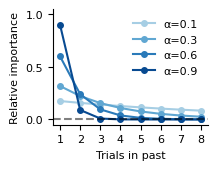

In [3]:
# ---------- Figure 1: Relative importance over last n=8 feedback ----------
n = 8
k = np.arange(1, n + 1)  # trials in past: 1..8
fig1, ax1 = plt.subplots(figsize=(width_in_small, height_in))

for color, a in zip(curve_colors, alphas):
    # Exponential recency weighting (normalized over the last n trials)
    w = a * (1 - a) ** (k - 1)
    w = w / w.sum()
    ax1.plot(k, w, marker='o', markersize=4, color=color, label=f'α={a}')

ax1.axhline(0, color='k', linestyle='--', alpha=0.5)
ax1.set_xlabel('Trials in past')
ax1.set_ylabel('Relative importance')
ax1.set_xticks(k)
ax1.set_yticks([0, 0.5, 1.0])
ax1.set_ylim(-0.05, 1.05)
ax1.legend(frameon=False)
despine(ax1)
#fig1.tight_layout()
fig1.savefig(os.path.join(FIGS_PATH, 'figS1a_relative_importance.svg'), bbox_inches='tight', transparent=True)

plt.show()

In [4]:
# Export source data (Supplementary Figure 1a)
import pandas as pd
from popy.source_data import export_source_data

# the plotted curves: weight of the outcome of k trials in the past, normalized over the last n = 8 trials
curves = [line for line in ax1.lines if line.get_label().startswith('α=')]
table_s1a = pd.DataFrame({'Trials in past': curves[0].get_xdata()})
for line in curves:
    table_s1a[f'Relative importance, alpha = {line.get_label()[2:]}'] = line.get_ydata()
export_source_data('Supplementary Figure 1a', table_s1a,
                   'Relative importance of past outcomes in the value estimated by the delta learning rule, for four learning rates alpha: '
                   'weight alpha * (1 - alpha)^(k - 1) of the outcome k trials in the past, normalized to sum to 1 over the last 8 trials. '
                   'Analytical curves (no data, no error bars).')

Supplementary Figure 1a: source data saved (8 rows)


---
# Supplementary Fig. 1b

/var/folders/y6/tr60_9y13514h8wvk15tr4gc0000gn/T/ipykernel_93645/63505602.py:76: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig2.tight_layout()


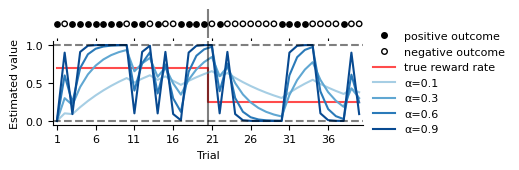

In [5]:
# ---------- Figure 2: Stochastic outcomes with flipping reward rate ----------
T = 40
block_size = 20
trials = np.arange(1, T + 1)

# True reward-rate schedule (flip every block_size trials)
reward_rate = np.array([0.7 if ((i - 1) // block_size) % 2 == 0 else 0.25
                        for i in range(1, T + 1)])

# Sample outcomes stochastically from the true rates
'''random_int = np.random.randint(0, 10000)
print(f"Random seed for outcomes: {random_int}")'''
rng2 = np.random.default_rng(7708)
outcomes = rng2.binomial(1, reward_rate).tolist()

# Figure with a small outcome strip on top + main panel below (same overall height)
fig2 = plt.figure(figsize=(width_in_large, height_in))
gs = fig2.add_gridspec(nrows=2, ncols=1, height_ratios=[0.35, 1.0], hspace=0.05)
ax2_top = fig2.add_subplot(gs[0])
ax2 = fig2.add_subplot(gs[1], sharex=ax2_top)

# --- Top outcome strip (filled = positive, empty = negative) ---
ax2_top.set_xlim(0.5, T + 0.5)
ax2_top.set_ylim(0, 1)
for i, r in enumerate(outcomes, start=1):
    if r == 1:
        ax2_top.scatter(i, 0.5, s=15, facecolor='k', edgecolor='k')
    else:
        ax2_top.scatter(i, 0.5, s=15, facecolor='none', edgecolor='k')
# Mark block boundaries on the strip
for xline in np.arange(block_size + 0.5, T + 0.5, block_size):
    ax2_top.axvline(xline, color='k', linestyle='-', alpha=0.5)
# Hide all decoration on the strip
ax2_top.set_xticks([])
ax2_top.set_yticks([])
for spine in ax2_top.spines.values():
    spine.set_visible(False)

# --- Main panel: values under delta-rule for four learning rates ---
ax2.set_xlim(0.5, T + 0.5)
ax2.set_ylim(-0.05, 1.05)

# True reward rate in the background (red step line)
ax2.step(trials, reward_rate, where='mid', color='red', linewidth=1.5, alpha=0.7,
         label='true reward rate', zorder=0)

for color, a in zip(curve_colors, alphas):
    V = 0.0
    values = []
    for r in outcomes:
        values.append(V)                 # value at the start of trial t
        V = V + a * (r - V)              # update with outcome r
    ax2.plot(trials, values, color=color, linewidth=1.5, label=f'α={a}')

# Reference lines and block boundaries
ax2.axhline(0, color='k', linestyle='--', alpha=0.5)
ax2.axhline(1, color='k', linestyle='--', alpha=0.5)
for xline in np.arange(block_size + 0.5, T + 0.5, block_size):
    ax2.axvline(xline, color='k', linestyle='-', alpha=0.5)

ax2.set_xticks(trials[::5])
ax2.set_xlabel('Trial')
ax2.set_ylabel('Estimated value')

# Legend with outcome markers + alpha curves
m_filled = plt.Line2D([], [], color='k', marker='o', linestyle='None',
                      markersize=4, label='positive outcome')
m_empty = plt.Line2D([], [], color='k', marker='o', linestyle='None',
                     markersize=4, markerfacecolor='none', label='negative outcome')
handles, labels = ax2.get_legend_handles_labels()
handles = [m_filled, m_empty] + handles
labels = [m.get_label() for m in [m_filled, m_empty]] + labels
ax2.legend(handles, labels, frameon=False, loc='center left', bbox_to_anchor=(1, 0.5))

despine(ax2)
fig2.tight_layout()
fig2.savefig(os.path.join(FIGS_PATH, 'figS1b_session_values.svg'), bbox_inches='tight', transparent=True)

plt.show()

In [6]:
# Export source data (Supplementary Figure 1b)
from popy.source_data import export_source_data

# the plotted lines: true reward rate (red step line) and the value estimated with each learning rate
lines = {line.get_label(): line for line in ax2.lines}
table_s1b = pd.DataFrame({
    'Trial': trials,
    'Outcome (1: rewarded, 0: unrewarded)': outcomes,
    'True reward rate': lines['true reward rate'].get_ydata(),
})
for a in alphas:
    table_s1b[f'Estimated value, alpha = {a}'] = lines[f'α={a}'].get_ydata()
export_source_data('Supplementary Figure 1b', table_s1b,
                   'Example sequence of 40 stochastic binary outcomes (reward probability 0.7 in trials 1-20 and 0.25 in trials 21-40; '
                   'outcomes drawn with a fixed random seed) and the value estimated by the delta learning rule V <- V + alpha * (R - V) '
                   'for four learning rates (value at the start of each trial, before the update with its outcome; initial value 0). '
                   'Simulation, no error bars.')

Supplementary Figure 1b: source data saved (40 rows)
